In [1]:
# Objective:
# Compare measurement results from different tools
# using the same wafers.
#
# Statistical methods:
# 1. Paired measurement comparison
# 2. Paired t-test
# 3. Bland-Altman analysis
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ttest_rel
from pathlib import Path

ROOT = Path.cwd().parent
DATA_DIR = ROOT / "content"
FIG_DIR = ROOT / "content" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
tool = pd.read_csv(
    DATA_DIR / "tool_matching_data.csv"
)
sns.set_theme(style="whitegrid")

In [2]:
# ============================================================
# 1. Calculate Mean Measurement for Each Wafer and Tool
# ============================================================

# Each wafer is measured twice by each tool.
# Calculate the average to obtain one value per wafer per tool.
wafer_tool = (
    tool.groupby(["wafer_id", "tool_id"])
    .agg(mean_measured_cd=("measured_cd_nm", "mean"),
        true_cd=("true_cd_nm", "mean")
    )
    .reset_index()
)

print("Wafer-level Tool Matching Data:")
print(wafer_tool.head())

# ============================================================
# 2. Convert Data into Wide Format
# ============================================================

# Each row represents one wafer.
# Each column represents one measurement tool.

wide_tool = wafer_tool.pivot(
    index="wafer_id",
    columns="tool_id",
    values="mean_measured_cd"
)

print("\nPaired Tool Measurement:")
print(wide_tool.head())

Wafer-level Tool Matching Data:
  wafer_id tool_id  mean_measured_cd    true_cd
0     W001  Tool_A         43.876814  43.979451
1     W001  Tool_B         44.261430  43.979451
2     W001  Tool_C         43.812613  43.979451
3     W002  Tool_A         45.142644  45.126832
4     W002  Tool_B         45.366574  45.126832

Paired Tool Measurement:
tool_id      Tool_A     Tool_B     Tool_C
wafer_id                                 
W001      43.876814  44.261430  43.812613
W002      45.142644  45.366574  44.909592
W003      44.044207  44.317990  43.918924
W004      44.896061  45.014489  44.625214
W005      45.255637  45.616968  45.130014


In [3]:
# ============================================================
# 3. Calculate Paired Differences
# ============================================================
# Compare Tool B and Tool C against Tool A.
#
# Positive difference: The first tool measures a higher CD than Tool A.
# Negative difference: The first tool measures a lower CD than Tool A.

wide_tool["B_minus_A"] = (
    wide_tool["Tool_B"] - wide_tool["Tool_A"]
)
wide_tool["C_minus_A"] = (
    wide_tool["Tool_C"] - wide_tool["Tool_A"]
)
wide_tool["B_minus_C"] = (
    wide_tool["Tool_B"] - wide_tool["Tool_C"]
)

print("\nPaired Differences Summary:")
print(wide_tool[ ["B_minus_A", "C_minus_A", "B_minus_C"]
    ].describe().round(4)
)


# ============================================================
# 4. Paired t-test
# ============================================================
# H0: Mean paired difference = 0
# H1: Mean paired difference != 0

comparisons = [
    ("Tool B vs Tool A", "Tool_B", "Tool_A"),
    ("Tool C vs Tool A", "Tool_C", "Tool_A"),
    ("Tool B vs Tool C", "Tool_B", "Tool_C")
]

results = []
for name, tool_1, tool_2 in comparisons:
    t_stat, p_value = ttest_rel(
        wide_tool[tool_1],
        wide_tool[tool_2]
    )

    # Calculate average paired difference
    mean_diff = (
        wide_tool[tool_1] - wide_tool[tool_2]
    ).mean()

    results.append({
        "Comparison": name,
        "Mean Difference (nm)": mean_diff,
        "t_statistic": t_stat,
        "p_value": p_value
    })

paired_test = pd.DataFrame(results)

print("\nPaired t-test Results:")
print(paired_test.round(5))


Paired Differences Summary:
tool_id  B_minus_A  C_minus_A  B_minus_C
count      30.0000    30.0000    30.0000
mean        0.2534    -0.1756     0.4290
std         0.0908     0.1336     0.0994
min         0.0583    -0.4048     0.2421
25%         0.1845    -0.2611     0.3612
50%         0.2646    -0.1617     0.4250
75%         0.2981    -0.0809     0.4848
max         0.4319     0.1898     0.6456

Paired t-test Results:
         Comparison  Mean Difference (nm)  t_statistic  p_value
0  Tool B vs Tool A               0.25342     15.28735      0.0
1  Tool C vs Tool A              -0.17561     -7.20160      0.0
2  Tool B vs Tool C               0.42903     23.63222      0.0


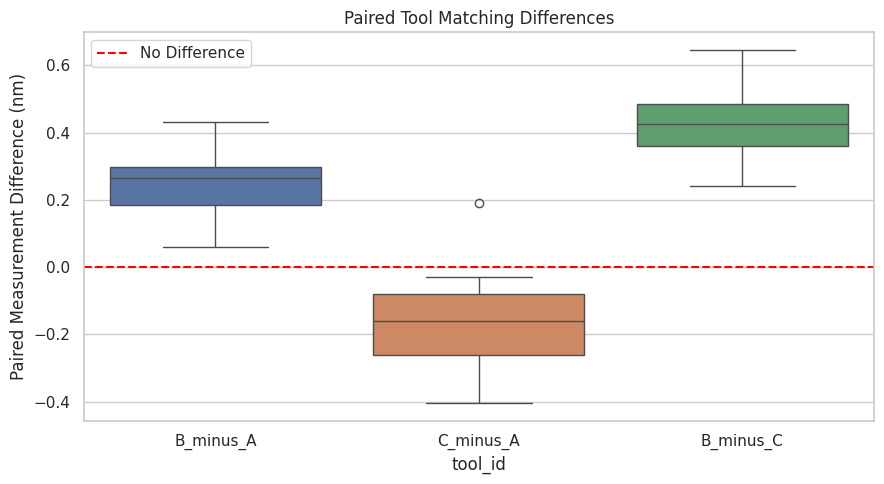

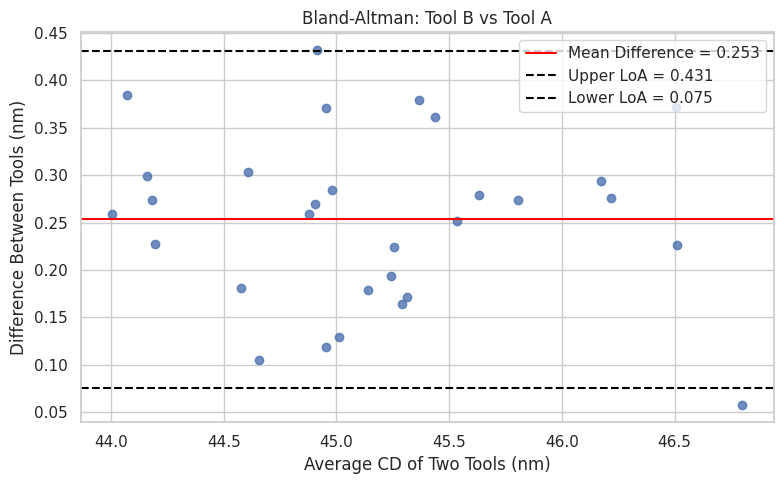

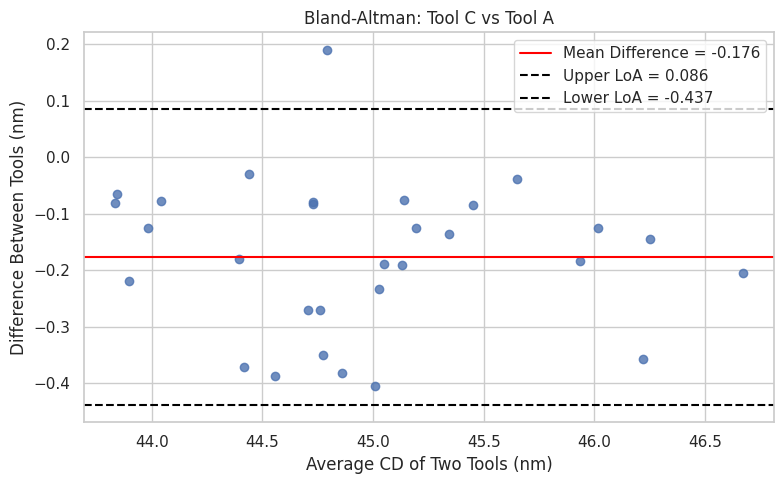


Bland-Altman Summary:
         Comparison  Mean Difference  SD Difference  Upper LoA  Lower LoA
0  Tool B vs Tool A           0.2534         0.0908     0.4314     0.0755
1  Tool C vs Tool A          -0.1756         0.1336     0.0862    -0.4374


In [4]:
# ============================================================
# 5. Visualize Paired Differences
# ============================================================
plt.figure(figsize=(9, 5))
sns.boxplot(data=wide_tool[
        ["B_minus_A", "C_minus_A", "B_minus_C"]
    ]
)

plt.axhline( 0,
    color="red",
    linestyle="--",
    label="No Difference"
)

plt.ylabel("Paired Measurement Difference (nm)")
plt.title("Paired Tool Matching Differences")
plt.legend()
plt.tight_layout()

plt.savefig( FIG_DIR / "06_paired_tool_differences.png", dpi=300)
plt.show()


# ============================================================
# 6. Bland-Altman Analysis
# ============================================================
# Bland-Altman analysis evaluates agreement between two measurement methods.
#
# X-axis: Average of two tools
# Y-axis: Difference between two tools
#
# Mean difference: Systematic bias
# Limits of Agreement (LoA):
# Mean difference +/- 1.96 * SD of differences

def bland_altman(data_a, data_b, label_a, label_b, filename):
    average = (data_a + data_b) / 2
    difference = data_a - data_b

    # Calculate mean bias and standard deviation
    mean_diff = difference.mean()
    sd_diff = difference.std(ddof=1)

    # Calculate 95% limits of agreement
    upper_loa = mean_diff + 1.96 * sd_diff
    lower_loa = mean_diff - 1.96 * sd_diff

    # Plot
    plt.figure(figsize=(8, 5))

    plt.scatter(average, difference, alpha=0.8)
    plt.axhline(
        mean_diff,
        color="red",
        linestyle="-",
        label=f"Mean Difference = {mean_diff:.3f}"
    )

    plt.axhline(
        upper_loa,
        color="black",
        linestyle="--",
        label=f"Upper LoA = {upper_loa:.3f}"
    )

    plt.axhline(
        lower_loa,
        color="black",
        linestyle="--",
        label=f"Lower LoA = {lower_loa:.3f}"
    )

    plt.xlabel("Average CD of Two Tools (nm)")
    plt.ylabel("Difference Between Tools (nm)")
    plt.title(f"Bland-Altman: {label_a} vs {label_b}"
    )

    plt.legend()
    plt.tight_layout()
    plt.savefig(FIG_DIR / filename, dpi=300)
    plt.show()

    return {
        "Comparison": f"{label_a} vs {label_b}",
        "Mean Difference": mean_diff,
        "SD Difference": sd_diff,
        "Upper LoA": upper_loa,
        "Lower LoA": lower_loa
    }


# Compare Tool B with Tool A
ba_ba = bland_altman(
    wide_tool["Tool_B"],
    wide_tool["Tool_A"],
    "Tool B",
    "Tool A",
    "07_bland_altman_B_A.png"
)

# Compare Tool C with Tool A
ba_ca = bland_altman(
    wide_tool["Tool_C"],
    wide_tool["Tool_A"],
    "Tool C",
    "Tool A",
    "08_bland_altman_C_A.png"
)

print("\nBland-Altman Summary:")
print(pd.DataFrame([ba_ba, ba_ca]).round(4))


In [5]:
# ============================================================
# 7. Export Results
# ============================================================

wide_tool.to_csv(
    DATA_DIR / "paired_tool_data.csv"
)

paired_test.to_csv(
    DATA_DIR / "paired_tool_ttest.csv",
    index=False
)

print("\nPaired Tool Matching Analysis Completed.")



Paired Tool Matching Analysis Completed.


**結果**

***1.   Paired Difference：***
- Tool B 相較 Tool A，平均高出約 0.253 nm。
- Tool C 相較 Tool A，平均低約 0.176 nm。
- Tool B 相較 Tool C，平均高出約 0.429 nm。

尤其 B − A 的最小值仍是 +0.0583 nm，代表在這 30 片 wafer 中，Tool B 每次的 wafer-level 平均值都高於 Tool A。

C − A 則有一個例外：最大值 +0.1898 nm，表示並不是每一片 wafer 都是 C 低於 A，但整體平均仍然明顯偏低。

***2.   Paired t-test:***
- B vs A:	t-stats 15.287	,p-value 接近 0
- C vs A:	t-stats -7.202	,p-value 接近 0
- B vs C:	t-stats 23.632	,p-value 接近 0

這三組比較都具有高度統計顯著性。換句話說，在目前的模擬資料與配對檢定假設下，有很強的證據認為三台設備的平均量測結果存在差異。但*統計顯著 ≠ 工程上不可接受*，要看實際的 CD tolerance 和量測系統標準。

***3.  Bland–Altman：***

B vs A (存在正向偏差)
- 平均差異：+0.2534 nm
- 95% LoA：約 +0.0755 至 +0.4314 nm
整個 LoA 區間都在 0 以上，表示 Tool B 相對 Tool A 的量測值整體偏高。

C vs A
- 平均差異：-0.1756 nm
- 95% LoA：約 -0.4374 至 +0.0862 nm
平均差異為負，代表 Tool C 整體偏低，但 LoA 跨過 0，表示不同 wafer 之間的差異方向並非完全一致。

注意： LoA 是量測差異的估計範圍，不是信賴區間，也不是設備允收規格。


**結論**

設 Tool A 是目前的參考設備：
1. Tool B 存在約 +0.25 nm 的系統性偏差。
2. Tool C 存在約 -0.18 nm 的平均偏差。
3. Tool B 與 Tool C 的平均差異約 0.43 nm。
4. 三組配對檢定均顯示統計顯著差異。
5. 若三台設備要共同量測同一產品，應進一步評估設備間的 offset correction 與允收標準。

模擬資料中有真值，所以還能回頭確認各台設備的 accuracy；真實工廠通常還需要參考標準件或校正程序。